In [1]:
# CELL 1 — ENVIRONMENT VERIFICATION
# No package installation or upgrades required.

import sys

print("Python version:", sys.version)

try:
    import torch
    import transformers
    import matplotlib

    print("PyTorch:", torch.__version__)
    print("Transformers:", transformers.__version__)
    print("Matplotlib:", matplotlib.__version__)

    print("\nAll essential libraries are available.")

except ImportError as error:
    print("Missing required library:", error)
    raise

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
PyTorch: 2.11.0+cpu
Transformers: 5.21.0
Matplotlib: 3.10.0

All essential libraries are available.


In [2]:
# CELL 2 — IMPORT LIBRARIES AND CONFIGURATION

import time
import random
import re
import csv

import torch
import matplotlib.pyplot as plt

from collections import Counter
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# Set random seed
SEED = 42

random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Configure CPU/GPU
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Execution device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU.")

print("Library configuration completed successfully.")

PyTorch version: 2.11.0+cpu
Execution device: cpu
Running on CPU.
Library configuration completed successfully.


In [3]:
# CELL 3 — LOAD PRETRAINED SUMMARISATION MODEL

MODEL_NAME = "sshleifer/distilbart-cnn-12-6"

print("Downloading tokenizer and pretrained model...")
print("This may take a few minutes during the first execution.")

start_time = time.time()

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Load pretrained sequence-to-sequence model
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)

# Move model to selected device
model = model.to(DEVICE)

# Set evaluation mode
model.eval()

model_load_time = time.time() - start_time

print("\nMODEL LOADED SUCCESSFULLY")
print("Model:", MODEL_NAME)
print("Device:", DEVICE)
print(f"Loading time: {model_load_time:.2f} seconds")

This may take a few minutes during the first execution.


config.json:   0%|          | 0.00/1.80k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.22GB            

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

[transformers] Please make sure the generation config includes `forced_bos_token_id=0`. 


Loading weights:   0%|          | 0/358 [00:00<?, ?it/s]


MODEL LOADED SUCCESSFULLY
Model: sshleifer/distilbart-cnn-12-6
Device: cpu
Loading time: 56.60 seconds


In [4]:
# CELL 4 — INPUT TEXTS AND REFERENCE SUMMARIES

articles = [
    """
    Renewable energy sources such as solar and wind power are increasingly
    used to reduce dependence on fossil fuels. Governments are supporting
    clean-energy projects through investment, incentives and infrastructure
    development. Challenges include storage, grid integration and the
    variability of weather-dependent generation.
    """,

    """
    Cybersecurity has become an important concern as businesses and
    individuals rely increasingly on connected systems. Common threats
    include phishing, ransomware and data theft. Organisations can reduce
    risk through software updates, multi-factor authentication, employee
    awareness training, backups and incident response planning.
    """,

    """
    Urban public transport can reduce traffic congestion and emissions when
    it is reliable, affordable and accessible. Investment in buses, rail
    networks, safe walking routes and integrated ticketing can encourage
    people to use public transport. Effective planning must consider
    population growth, service frequency and connections between suburbs.
    """
]

references = [
    """
    Solar and wind energy are expanding as alternatives to fossil fuels,
    but storage, grid integration and weather variability remain challenges.
    """,

    """
    Cybersecurity risks include phishing, ransomware and data theft.
    Updates, multi-factor authentication, awareness training and backups
    help reduce risk.
    """,

    """
    Reliable and accessible public transport can reduce congestion and
    emissions. Investment and integrated planning encourage greater use.
    """
]

print("Number of input documents:", len(articles))

for index, article in enumerate(articles, start=1):
    print(f"\nDOCUMENT {index}")
    print(article.strip())
    print("-" * 70)

Number of input documents: 3

DOCUMENT 1
Renewable energy sources such as solar and wind power are increasingly
    used to reduce dependence on fossil fuels. Governments are supporting
    clean-energy projects through investment, incentives and infrastructure
    development. Challenges include storage, grid integration and the
    variability of weather-dependent generation.
----------------------------------------------------------------------

DOCUMENT 2
Cybersecurity has become an important concern as businesses and
    individuals rely increasingly on connected systems. Common threats
    include phishing, ransomware and data theft. Organisations can reduce
    risk through software updates, multi-factor authentication, employee
    awareness training, backups and incident response planning.
----------------------------------------------------------------------

DOCUMENT 3
Urban public transport can reduce traffic congestion and emissions when
    it is reliable, affordable and 

In [5]:
# CELL 5 — TEXT SUMMARISATION

def generate_summary(text, max_length=80, min_length=15):

    # Tokenise the input document
    inputs = tokenizer(
        text,
        return_tensors="pt",
        max_length=1024,
        truncation=True
    )

    # Transfer inputs to CPU/GPU
    inputs = {
        key: value.to(DEVICE)
        for key, value in inputs.items()
    }

    # Generate summary
    with torch.inference_mode():

        summary_ids = model.generate(
            **inputs,
            max_new_tokens=max_length,
            min_new_tokens=min_length,
            num_beams=4,
            early_stopping=True,
            do_sample=False
        )

    # Convert generated tokens into readable text
    summary = tokenizer.decode(
        summary_ids[0],
        skip_special_tokens=True
    )

    return summary


generated_summaries = []
inference_times = []

# Generate summaries for all documents
for index, article in enumerate(articles, start=1):

    start_time = time.time()

    summary = generate_summary(article)

    elapsed_time = time.time() - start_time

    generated_summaries.append(summary)
    inference_times.append(elapsed_time)

    print(f"\nDOCUMENT {index}")
    print("=" * 80)

    print("\nORIGINAL TEXT:")
    print(article.strip())

    print("\nGENERATED SUMMARY:")
    print(summary)

    print(f"\nInference time: {elapsed_time:.2f} seconds")

    print("=" * 80)

print("\nAll summaries generated successfully.")

[transformers] Both `max_new_tokens` (=80) and `max_length`(=142) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `min_new_tokens` (=15) and `min_length`(=56) seem to have been set. `min_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



DOCUMENT 1

ORIGINAL TEXT:
Renewable energy sources such as solar and wind power are increasingly
    used to reduce dependence on fossil fuels. Governments are supporting
    clean-energy projects through investment, incentives and infrastructure
    development. Challenges include storage, grid integration and the
    variability of weather-dependent generation.

GENERATED SUMMARY:
 Governments are supporting clean-energy projects through investment, incentives and infrastructure . Challenges include storage, grid integration and variability of weather-dependent generation .

Inference time: 11.64 seconds


[transformers] Both `max_new_tokens` (=80) and `max_length`(=142) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `min_new_tokens` (=15) and `min_length`(=56) seem to have been set. `min_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



DOCUMENT 2

ORIGINAL TEXT:
Cybersecurity has become an important concern as businesses and
    individuals rely increasingly on connected systems. Common threats
    include phishing, ransomware and data theft. Organisations can reduce
    risk through software updates, multi-factor authentication, employee
    awareness training, backups and incident response planning.

GENERATED SUMMARY:
 Cybersecurity has become an important concern as businesses and individuals rely increasingly on connected systems . Common threats include phishing, ransomware and data theft . Organisations can reduce risk through software updates, multi-factor authentication and employee awareness training .

Inference time: 8.82 seconds


[transformers] Both `max_new_tokens` (=80) and `max_length`(=142) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `min_new_tokens` (=15) and `min_length`(=56) seem to have been set. `min_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



DOCUMENT 3

ORIGINAL TEXT:
Urban public transport can reduce traffic congestion and emissions when
    it is reliable, affordable and accessible. Investment in buses, rail
    networks, safe walking routes and integrated ticketing can encourage
    people to use public transport. Effective planning must consider
    population growth, service frequency and connections between suburbs.

GENERATED SUMMARY:
 Urban public transport can reduce traffic congestion and emissions when it is reliable, affordable and accessible . Investment in buses, rail networks, safe walking routes and integrated ticketing can encourage people to use public transport .

Inference time: 6.38 seconds

All summaries generated successfully.


In [6]:
# CELL 6 — ROUGE EVALUATION

def tokenize_text(text):
    """Convert text into lowercase word tokens."""
    return re.findall(r"\b\w+\b", text.lower())


def calculate_rouge_n(reference, prediction, n):

    ref_tokens = tokenize_text(reference)
    pred_tokens = tokenize_text(prediction)

    ref_ngrams = Counter(
        tuple(ref_tokens[i:i+n])
        for i in range(len(ref_tokens) - n + 1)
    )

    pred_ngrams = Counter(
        tuple(pred_tokens[i:i+n])
        for i in range(len(pred_tokens) - n + 1)
    )

    overlap = sum((ref_ngrams & pred_ngrams).values())

    total_ref = sum(ref_ngrams.values())
    total_pred = sum(pred_ngrams.values())

    if total_ref == 0 or total_pred == 0:
        return 0.0

    precision = overlap / total_pred
    recall = overlap / total_ref

    if precision + recall == 0:
        return 0.0

    return 2 * precision * recall / (precision + recall)


def calculate_rouge_l(reference, prediction):

    ref_tokens = tokenize_text(reference)
    pred_tokens = tokenize_text(prediction)

    m = len(ref_tokens)
    n = len(pred_tokens)

    # Longest Common Subsequence calculation
    dp = [[0] * (n + 1) for _ in range(m + 1)]

    for i in range(1, m + 1):
        for j in range(1, n + 1):

            if ref_tokens[i-1] == pred_tokens[j-1]:
                dp[i][j] = dp[i-1][j-1] + 1

            else:
                dp[i][j] = max(
                    dp[i-1][j],
                    dp[i][j-1]
                )

    lcs_length = dp[m][n]

    if m == 0 or n == 0:
        return 0.0

    precision = lcs_length / n
    recall = lcs_length / m

    if precision + recall == 0:
        return 0.0

    return 2 * precision * recall / (precision + recall)


# Evaluate generated summaries
results = []

for index, (reference, prediction) in enumerate(
    zip(references, generated_summaries),
    start=1
):

    rouge1 = calculate_rouge_n(reference, prediction, 1)
    rouge2 = calculate_rouge_n(reference, prediction, 2)
    rougeL = calculate_rouge_l(reference, prediction)

    results.append({
        "Document": index,
        "ROUGE-1 F1": rouge1,
        "ROUGE-2 F1": rouge2,
        "ROUGE-L F1": rougeL,
        "Inference Time": inference_times[index-1]
    })


# Display individual evaluation results
print("INDIVIDUAL DOCUMENT EVALUATION")
print("-" * 80)

for result in results:
    print(result)


# Calculate average scores
mean_rouge1 = sum(r["ROUGE-1 F1"] for r in results) / len(results)
mean_rouge2 = sum(r["ROUGE-2 F1"] for r in results) / len(results)
mean_rougeL = sum(r["ROUGE-L F1"] for r in results) / len(results)

print("\nAVERAGE ROUGE SCORES")
print("-" * 80)

print(f"ROUGE-1 F1: {mean_rouge1:.4f}")
print(f"ROUGE-2 F1: {mean_rouge2:.4f}")
print(f"ROUGE-L F1: {mean_rougeL:.4f}")

print(
    "\nAverage inference time:",
    round(sum(inference_times) / len(inference_times), 2),
    "seconds"
)

INDIVIDUAL DOCUMENT EVALUATION
--------------------------------------------------------------------------------
{'Document': 1, 'ROUGE-1 F1': 0.47619047619047616, 'ROUGE-2 F1': 0.15, 'ROUGE-L F1': 0.28571428571428564, 'Inference Time': 11.639004230499268}
{'Document': 2, 'ROUGE-1 F1': 0.5714285714285715, 'ROUGE-2 F1': 0.3703703703703704, 'ROUGE-L F1': 0.4642857142857143, 'Inference Time': 8.823745965957642}
{'Document': 3, 'ROUGE-1 F1': 0.5882352941176471, 'ROUGE-2 F1': 0.2857142857142857, 'ROUGE-L F1': 0.4705882352941177, 'Inference Time': 6.375024318695068}

AVERAGE ROUGE SCORES
--------------------------------------------------------------------------------
ROUGE-1 F1: 0.5453
ROUGE-2 F1: 0.2687
ROUGE-L F1: 0.4069

Average inference time: 8.95 seconds


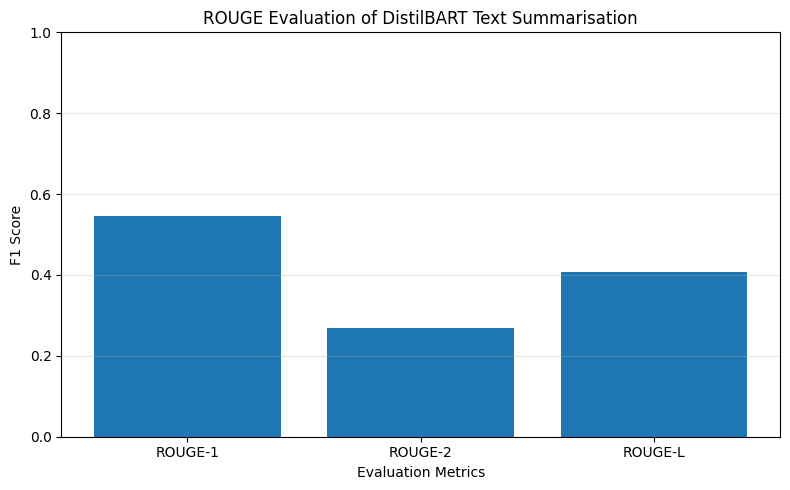

In [7]:
# CELL 7 — ROUGE SCORE VISUALISATION

metric_names = [
    "ROUGE-1",
    "ROUGE-2",
    "ROUGE-L"
]

metric_values = [
    mean_rouge1,
    mean_rouge2,
    mean_rougeL
]

plt.figure(figsize=(8, 5))

plt.bar(metric_names, metric_values)

plt.ylim(0, 1)

plt.xlabel("Evaluation Metrics")
plt.ylabel("F1 Score")

plt.title("ROUGE Evaluation of DistilBART Text Summarisation")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

TEXT COMPRESSION ANALYSIS
----------------------------------------------------------------------

Document 1
Original word count: 42
Summary word count: 22
Compression ratio: 47.62%

Document 2
Original word count: 41
Summary word count: 37
Compression ratio: 9.76%

Document 3
Original word count: 46
Summary word count: 34
Compression ratio: 26.09%


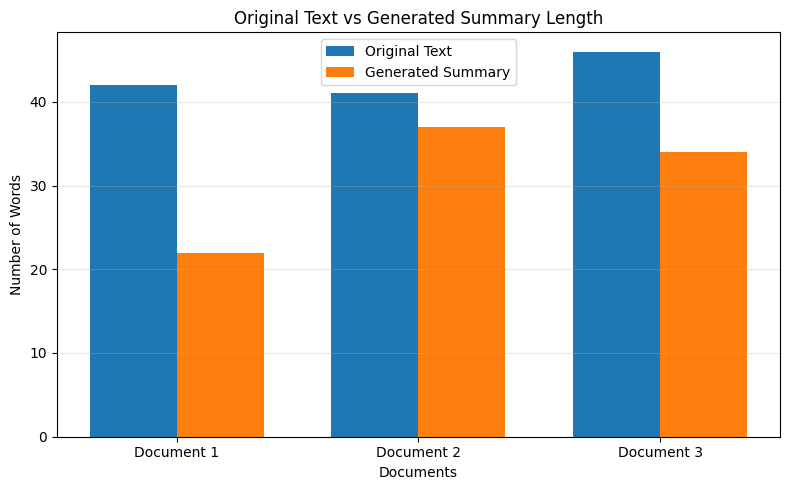


PROJECT EXECUTION COMPLETED SUCCESSFULLY
Saved files:
1. text_summarisation_results.csv
2. generated_summaries.txt


In [8]:
# CELL 8 — LENGTH COMPARISON AND RESULT EXPORT

input_words = [
    len(tokenize_text(article))
    for article in articles
]

summary_words = [
    len(tokenize_text(summary))
    for summary in generated_summaries
]

# Calculate compression ratios
compression_ratios = []

print("TEXT COMPRESSION ANALYSIS")
print("-" * 70)

for i in range(len(articles)):

    original = input_words[i]
    summary = summary_words[i]

    compression = (
        (original - summary) / original
    ) * 100

    compression_ratios.append(compression)

    print(f"\nDocument {i+1}")
    print("Original word count:", original)
    print("Summary word count:", summary)
    print(f"Compression ratio: {compression:.2f}%")


# Visualise input and summary lengths
x = list(range(len(articles)))

plt.figure(figsize=(8, 5))

plt.bar(
    [i - 0.18 for i in x],
    input_words,
    width=0.36,
    label="Original Text"
)

plt.bar(
    [i + 0.18 for i in x],
    summary_words,
    width=0.36,
    label="Generated Summary"
)

plt.xticks(
    x,
    [f"Document {i+1}" for i in x]
)

plt.xlabel("Documents")
plt.ylabel("Number of Words")

plt.title("Original Text vs Generated Summary Length")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# Save evaluation results as CSV
with open(
    "text_summarisation_results.csv",
    "w",
    newline="",
    encoding="utf-8"
) as file:

    writer = csv.DictWriter(
        file,
        fieldnames=list(results[0].keys())
    )

    writer.writeheader()
    writer.writerows(results)


# Save generated summaries
with open(
    "generated_summaries.txt",
    "w",
    encoding="utf-8"
) as file:

    for i, summary in enumerate(generated_summaries, start=1):

        file.write(f"DOCUMENT {i}\n")
        file.write(summary + "\n\n")


print("\nPROJECT EXECUTION COMPLETED SUCCESSFULLY")

print("Saved files:")
print("1. text_summarisation_results.csv")
print("2. generated_summaries.txt")